In [1]:
%load_ext autoreload
%autoreload 2
import os
import math
import random
import numpy as np
import random
import torch
import matplotlib.pyplot as plt

import draw,utils
import warnings
warnings.filterwarnings("ignore")

In [2]:
Train_filename = "Supervised_Train_syn2d_512.npy"
Valid_filename = "Supervised_Valid_syn2d_512.npy"
Modelname = "Supervised_syn2d_base"

In [3]:
num_sample = 4000
root_path = os.path.abspath(".")
dataset_name = 'dataset'
dataset_path = os.path.join(root_path,dataset_name)
train_dataset_path = os.path.join(dataset_path, "syn2d_512")

if os.path.exists(os.path.join(dataset_path,Train_filename)) is False:
    sample_name_list = []
    for i in range(num_sample):
        train_sample_file = f'{i}'
        sample_name_list.append(train_sample_file)
    train_set_ratio = 0.79999
    num_data_sample = len(sample_name_list)
    # 打乱数据集
    random.shuffle(sample_name_list)

    # 训练集/验证集划分
    valid_num = int(num_data_sample * (1-train_set_ratio))
    valid_list = random.sample(sample_name_list, valid_num)

    samples_train,samples_valid = [],[]
    for sample_name in sample_name_list[:num_sample]:
        if sample_name not in valid_list:
            samples_train.append(sample_name)
        else:
            samples_valid.append(sample_name)
            
    print(f'训练样本数量：{len(samples_train)}')
    print(f'验证样本数量：{len(samples_valid)}')
    
    np.save(os.path.join(dataset_path,Train_filename), samples_train)
    np.save(os.path.join(dataset_path,Valid_filename), samples_valid)

In [4]:
os.environ['CUDA_VISIBLE_DEVICES']= '3'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    num_GPU = torch.cuda.device_count()
    print(f"GPU 数量: {num_GPU}")
print(f"运行平台: {device}")
root_path = os.path.abspath('.')

GPU 数量: 1
运行平台: cuda


In [5]:
samples_train = np.load(os.path.join(dataset_path, Train_filename), allow_pickle=True)
samples_valid = np.load(os.path.join(dataset_path, Valid_filename), allow_pickle=True)
print(f"训练样本数量: {len(samples_train)}")
print(f"验证样本数量: {len(samples_valid)}")

train_sample_path = os.path.join(dataset_path, "syn2d_512")
input_attr_list = ["seis"]
rgt_attr_list = ["rgt"]
fault_attr_list = ["fault"]

训练样本数量: 3200
验证样本数量: 800


In [6]:
train_data =  utils.build_dataset_pretrain(samples_train, train_sample_path, 'Train',
                                           input_attr_list = input_attr_list,
                                           output_attr_list = rgt_attr_list, 
                                           output_attr_list2 = fault_attr_list)
valid_data =  utils.build_dataset_pretrain(samples_valid, train_sample_path, 'Valid',
                                           input_attr_list = input_attr_list,
                                           output_attr_list = rgt_attr_list, 
                                           output_attr_list2 = fault_attr_list)

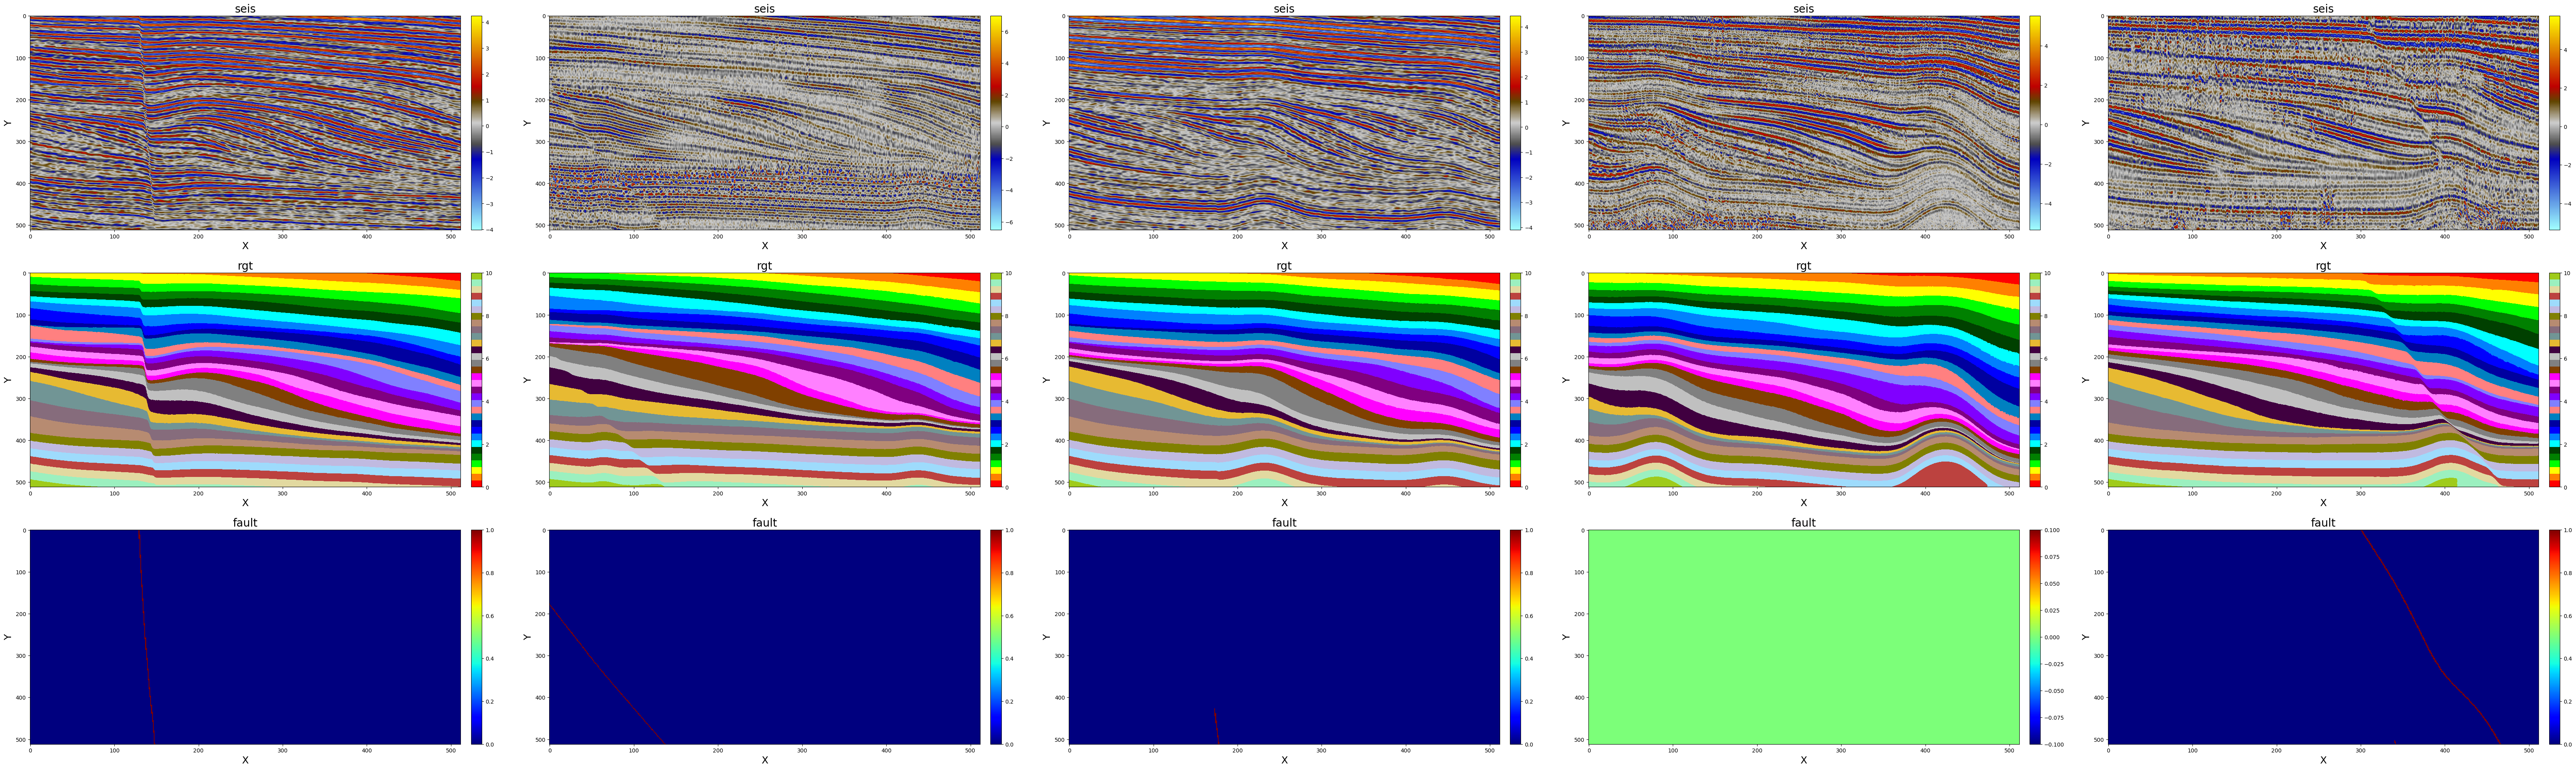

In [11]:
# plot
idxs = np.random.randint(0, len(train_data), size=5) 
batch_samples = [train_data[i] for i in idxs]
draw_attr_list = input_attr_list + rgt_attr_list + fault_attr_list
draw.draw_samples(batch_samples, draw_attr_list, cmap=[utils.getPetrelColors(),utils.getStrataColors(),"jet"],
                  methods=["bilinear","bilinear","nearest"])

In [8]:
import SFM_pretrain.model_rgt as models_rgt

model = models_rgt.vit_base_patch16(img_size=512, in_chans=1, num_classes=1, drop_path_rate=0.1)
state_dict = torch.load("./checkpoints/Pretrain_field2d_base/checkpoint-best.pth")['state_dict']
new_state_dict = {k.replace('module.', ''): v for k, v in state_dict.items()} # 移除module.前缀
model.load_state_dict(new_state_dict, strict=False)

# 并行模式
if torch.cuda.is_available():
    model = torch.nn.DataParallel(model, device_ids=range(num_GPU)).to(device)
else:
    model = model.to(device)
    
# 模型保存路径
checkpoint_path = os.path.join('checkpoints', Modelname)
if not os.path.exists(checkpoint_path):
    os.makedirs(checkpoint_path)
print(f"模型读取路径: {checkpoint_path}")

模型读取路径: checkpoints/Supervised_syn2d_base


In [9]:
# 定义训练参数
param = {}
param['epochs'] = 101     # 训练轮数
param['batch_size'] = 16   # 批大小
param['lr'] = 1e-3          # 学习率
# SGD
param['gamma'] = 0.9      # 学习率衰减系数
param['step_size'] = 50  # 学习率衰减间隔
param['momentum'] = 0.8    # 动量
# Adam
param['lr_factor'] = 0.5 # 学习因子
param['lr_patience'] = 2 # 容忍因子
param['weight_decay'] = 0 # 权重衰减(1e-4)

param['optimizer_type'] = 'Adam' # 优化器类型
param['checkpoint_path'] = checkpoint_path
param['disp_inter'] = 1 # 显示间隔
param['save_inter'] = 20 # 保存间隔

Epoch:0, TrainLoss:0.485344 <0.3445 & 0.1408>, ValidLoss: 0.214751, Learning rate: 0.001000
Epoch:1, TrainLoss:0.198149 <0.1103 & 0.0878>, ValidLoss: 0.181406, Learning rate: 0.001000
Epoch:2, TrainLoss:0.172329 <0.0917 & 0.0806>, ValidLoss: 0.222261, Learning rate: 0.001000
Epoch:3, TrainLoss:0.176593 <0.0946 & 0.0820>, ValidLoss: 0.202249, Learning rate: 0.001000
Epoch:4, TrainLoss:0.214188 <0.1225 & 0.0917>, ValidLoss: 0.205538, Learning rate: 0.001000
Epoch:5, TrainLoss:0.175788 <0.0944 & 0.0814>, ValidLoss: 0.167786, Learning rate: 0.001000
Epoch:6, TrainLoss:0.146246 <0.0724 & 0.0738>, ValidLoss: 0.165557, Learning rate: 0.000500
Epoch:7, TrainLoss:0.138864 <0.0667 & 0.0722>, ValidLoss: 0.139619, Learning rate: 0.000500
Epoch:8, TrainLoss:0.134298 <0.0636 & 0.0707>, ValidLoss: 0.167830, Learning rate: 0.000500
Epoch:9, TrainLoss:0.130970 <0.0612 & 0.0697>, ValidLoss: 0.121401, Learning rate: 0.000500
Epoch:10, TrainLoss:0.117878 <0.0521 & 0.0657>, ValidLoss: 0.116559, Learning ra

Epoch:89, TrainLoss:0.040460 <0.0047 & 0.0358>, ValidLoss: 0.064232, Learning rate: 0.000031
Epoch:90, TrainLoss:0.040229 <0.0045 & 0.0357>, ValidLoss: 0.062372, Learning rate: 0.000031
Epoch:91, TrainLoss:0.039767 <0.0043 & 0.0355>, ValidLoss: 0.062027, Learning rate: 0.000031
Epoch:92, TrainLoss:0.039745 <0.0044 & 0.0354>, ValidLoss: 0.062559, Learning rate: 0.000031
Epoch:93, TrainLoss:0.039713 <0.0044 & 0.0353>, ValidLoss: 0.062720, Learning rate: 0.000031
Epoch:94, TrainLoss:0.039993 <0.0047 & 0.0353>, ValidLoss: 0.062125, Learning rate: 0.000031
Epoch:95, TrainLoss:0.039465 <0.0043 & 0.0351>, ValidLoss: 0.062198, Learning rate: 0.000031
Epoch:96, TrainLoss:0.039578 <0.0045 & 0.0350>, ValidLoss: 0.062365, Learning rate: 0.000031
Epoch:97, TrainLoss:0.038924 <0.0041 & 0.0348>, ValidLoss: 0.062765, Learning rate: 0.000031
Epoch:98, TrainLoss:0.038824 <0.0041 & 0.0347>, ValidLoss: 0.063653, Learning rate: 0.000031
Epoch:99, TrainLoss:0.038711 <0.0041 & 0.0346>, ValidLoss: 0.063092, L

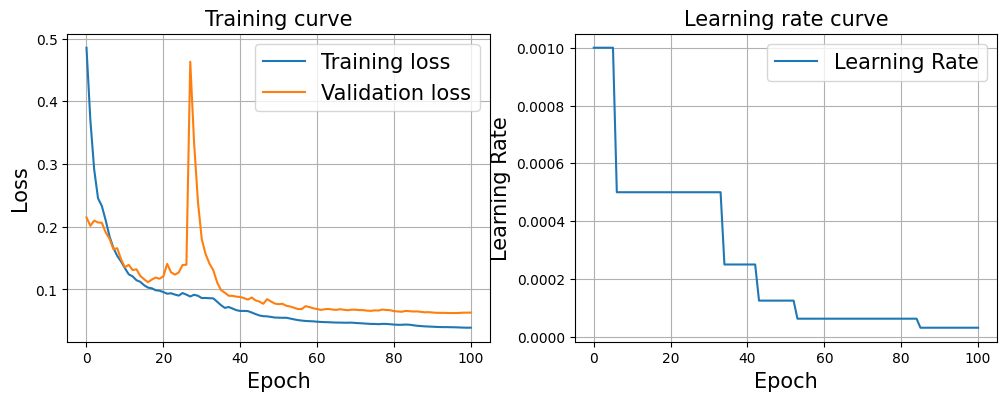

log has saved


In [10]:
model = utils.supervised_train_stage2(param, model, train_data, valid_data, input_attrs=["seis"],
                             output_attrs=["rgt"],output_attrs2=["fault"],plot=True)

In [ ]:
quit()